# Hoya Marketplace Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

plt.rcParams["figure.figsize"] = (8,5)

In [2]:
df = pd.read_csv("../data/shopee_hoya_clean.csv")

print(df.shape)

df.head()

(419, 11)


,product_name,variety,price,number_sold,location,rating,number_of_reviews,marketplace,scraping_date,product_url,shop_name
0,Hoya Cumigiana,Cumigiana,10000,5,Kab. Lumajang,4.90,497,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8915296529,Ngundang anggrek
1,Hoya Lacunosa Rimbun Bunganya Wangi,Lacunosa,12000,5,Kab. Lumajang,4.93,307,Shopee,2026-06-11,https://shopee.co.id/product/348755541/6579385658,Ngundang anggrek
2,Tanaman Hoya Carnosa Tricolor Atau Crimsom Pri...,Carnosa,34500,3,Kab. Bandung Barat,4.98,84,Shopee,2026-06-11,https://shopee.co.id/product/104126944/6352344959,Shofiflora
3,Sekulen Cluster Hoya Love Varigata Bercabang,Love,27500,7,Kab. Bandung Barat,4.94,48,Shopee,2026-06-11,https://shopee.co.id/product/163019197/2871789...,Kaktus Store
4,Hoya kuning cerah,Kuning,20000,3,Kab. Lumajang,4.88,97,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8787796573,Ngundang anggrek


In [3]:
df["estimated_revenue"] = (
    df["price"] *
    df["number_sold"]
)

### Dataset Summary

In [4]:
print("="*40)
print("DATASET SUMMARY")
print("="*40)

print(
    f"Total Listings: {len(df)}"
)

print(
    f"Unique Varieties: {df['variety'].nunique()}"
)

print(
    f"Unique Locations: {df['location'].nunique()}"
)

print(
    f"Total Estimated Revenue: Rp {df['estimated_revenue'].sum():,.0f}"
)

DATASET SUMMARY
Total Listings: 419
Unique Varieties: 175
Unique Locations: 50
Total Estimated Revenue: Rp 46,587,163


### Create variety dataset

In [5]:
exclude_varieties = [

    "Tidak Teridentifikasi",

    "Bunga",

    "Unknown",

    "Other"

]

df_variety = (
    df[
        ~df["variety"].isin(
            exclude_varieties
        )
    ]
    .copy()
)

print(df.shape)

print(df_variety.shape)

(419, 12)
(376, 12)


## Variety Analysis

In [6]:
variety_stats = (
    df_variety
    .groupby('variety')
    .agg(
        listings=('product_name','count'),
        sold=('number_sold','sum'),
        avg_price=('price','mean'),
        revenue=('estimated_revenue','sum')
    )
    .sort_values(
        'revenue',
        ascending=False
    )
)

variety_stats.head(20)

,listings,sold,avg_price,revenue
variety,,,,
Compacta,17,271,47588.235294,11653000
Carnosa,40,137,28292.950000,4669265
Macrophylla,14,248,22728.571429,4329500
Wayetii,2,34,55000.000000,1710000
Archboldiana,3,13,113833.333333,1516000
Love,15,35,25600.000000,970500
Gigas,1,3,250000.000000,750000
Curly,6,53,8666.666667,651000
Imperialis,3,6,76933.333333,584800


### Top Varieties by Number of Sold
"Which Hoya varieties are most traded?"

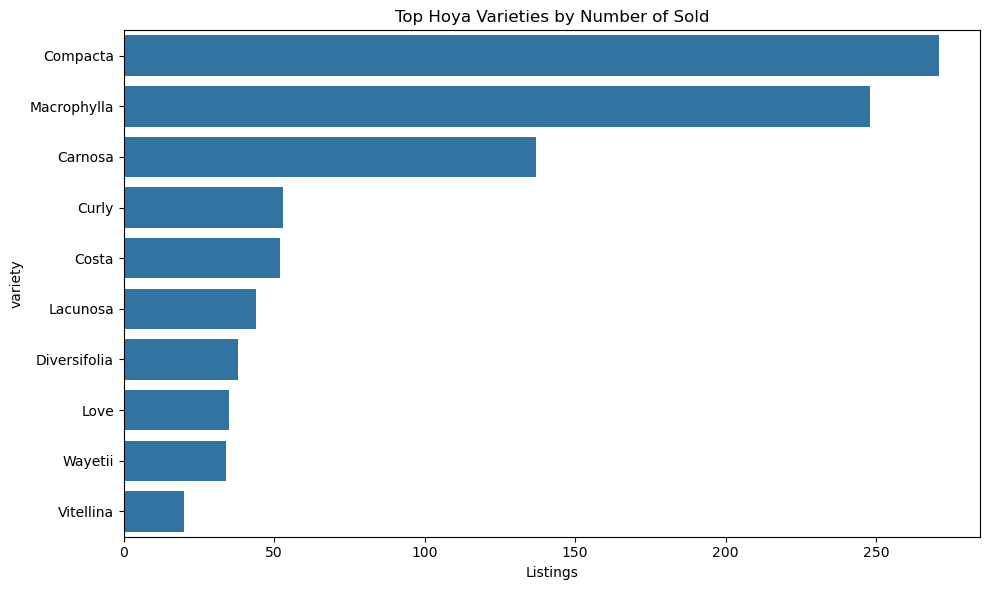

In [7]:
top_varieties = (
    df_variety
    .groupby("variety")["number_sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_varieties.values,
    y=top_varieties.index
)

plt.title(
    "Top Hoya Varieties by Number of Sold"
)

plt.xlabel("Listings")

plt.tight_layout()

plt.savefig(
    "../results/figure/top_varieties.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Variety Revenue Analysis

In [8]:
variety_stats = (
    df_variety
    .groupby("variety")
    .agg(
        listings=("variety","count"),
        sales=("number_sold","sum"),
        revenue=("estimated_revenue","sum")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

variety_stats.head(10)

,listings,sales,revenue
variety,,,
Compacta,17,271,11653000
Carnosa,40,137,4669265
Macrophylla,14,248,4329500
Wayetii,2,34,1710000
Archboldiana,3,13,1516000
Love,15,35,970500
Gigas,1,3,750000
Curly,6,53,651000
Imperialis,3,6,584800


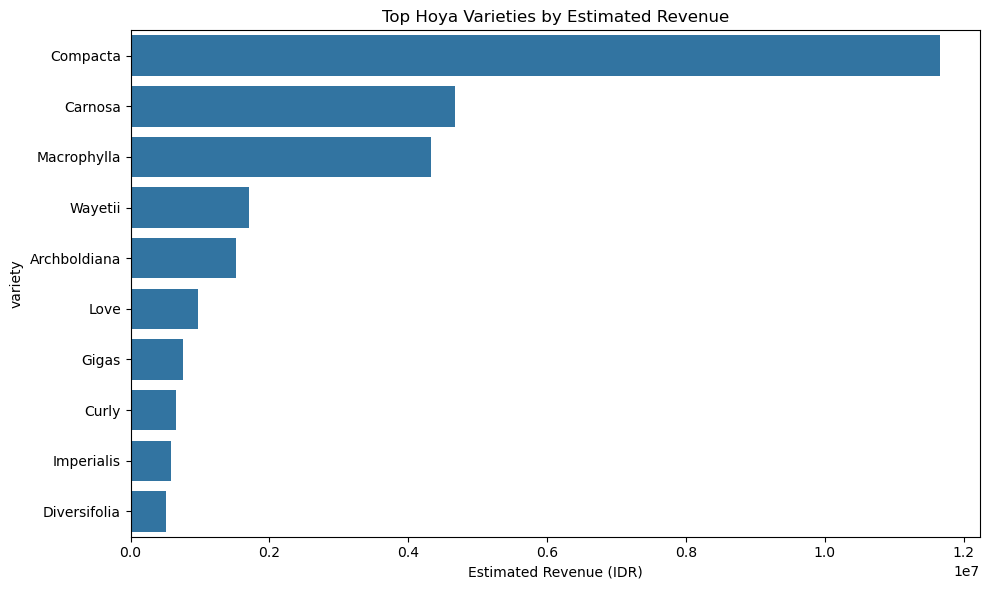

In [9]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=variety_stats.head(10),
    x="revenue",
    y=variety_stats.head(10).index
)

plt.title(
    "Top Hoya Varieties by Estimated Revenue"
)

plt.xlabel(
    "Estimated Revenue (IDR)"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/variety_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Average Price by Variety
"How does price vary among Hoya varieties?"

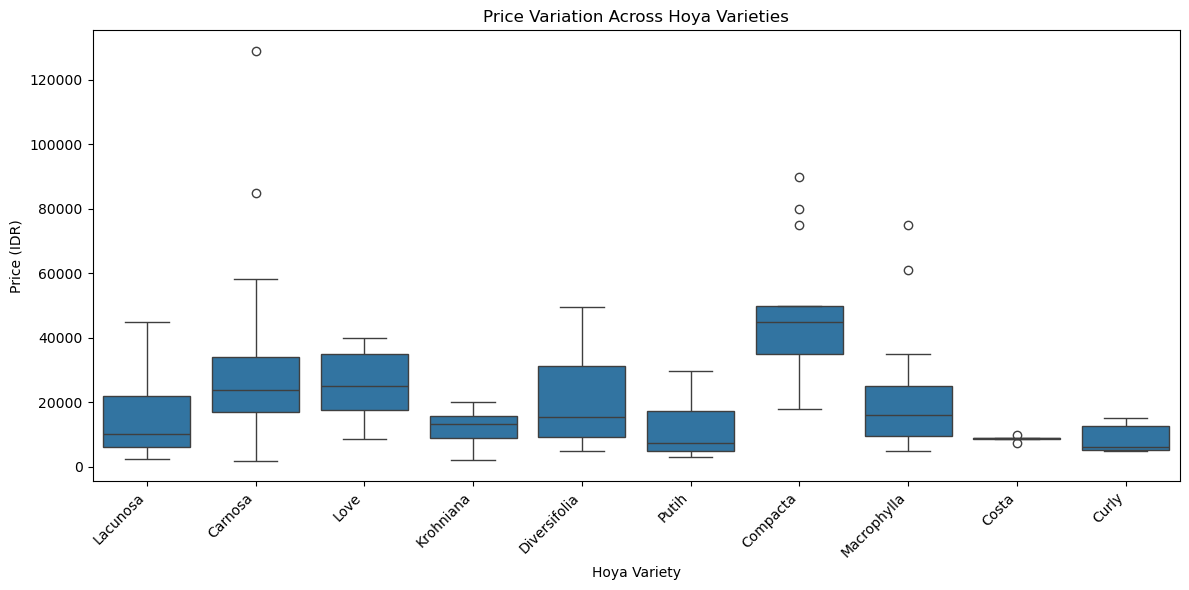

In [10]:
# Top 10 varieties by frequency
price_varieties = (
    df_variety["variety"]
    .value_counts()
    .head(10)
    .index
)

plot_df = (
    df_variety[
        df_variety["variety"].isin(price_varieties)
    ]
)

plt.figure(figsize=(12,6))

sns.boxplot(
    data=plot_df,
    x="variety",
    y="price"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.title(
    "Price Variation Across Hoya Varieties"
)

plt.xlabel(
    "Hoya Variety"
)

plt.ylabel(
    "Price (IDR)"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/price_variation_varieties.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Location Analysis
"Which regions are most selling Hoya?"

In [11]:
location_stats = (
    df
    .groupby("location")
    .agg(
        listings=("location","count"),
        sales=("number_sold","sum"),
        revenue=("estimated_revenue","sum")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

location_stats.head(10)

,listings,sales,revenue
location,,,
Kab. Cianjur,21,313,12245000
Kab. Bandung Barat,56,395,8859348
Kab. Purworejo,12,201,5555000
Kab. Gunung Kidul,10,21,3250000
Kab. Bogor,56,145,2738605
Kab. Sukabumi,32,67,2328500
Jakarta Pusat,10,47,1889870
Kab. Mojokerto,33,39,1341000
Jakarta Utara,5,89,1314140


### Top Locations by Revenue

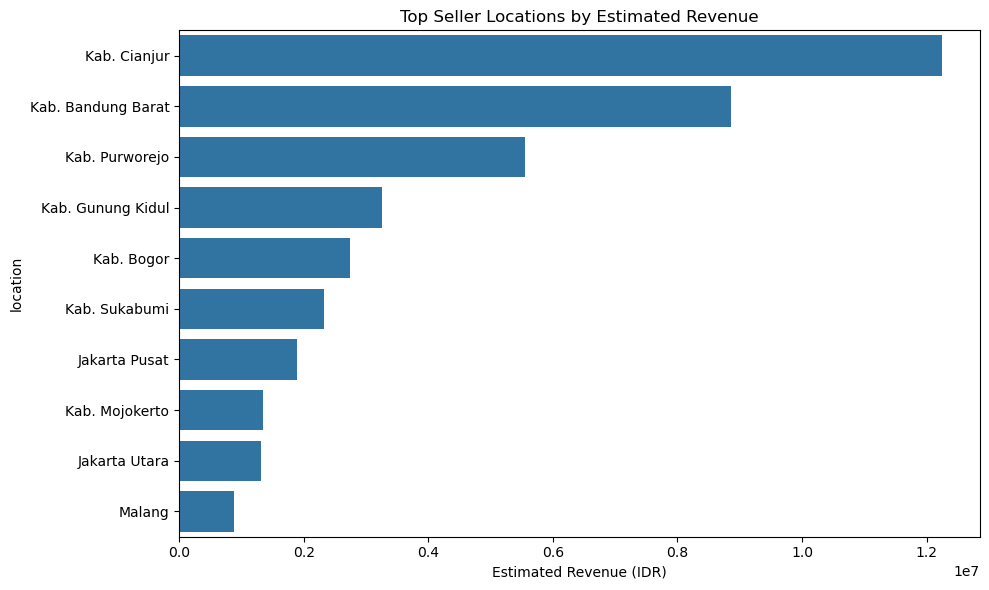

In [12]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=location_stats.head(10),
    x="revenue",
    y=location_stats.head(10).index
)

plt.title(
    "Top Seller Locations by Estimated Revenue"
)

plt.xlabel(
    "Estimated Revenue (IDR)"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/location_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Price Distribution

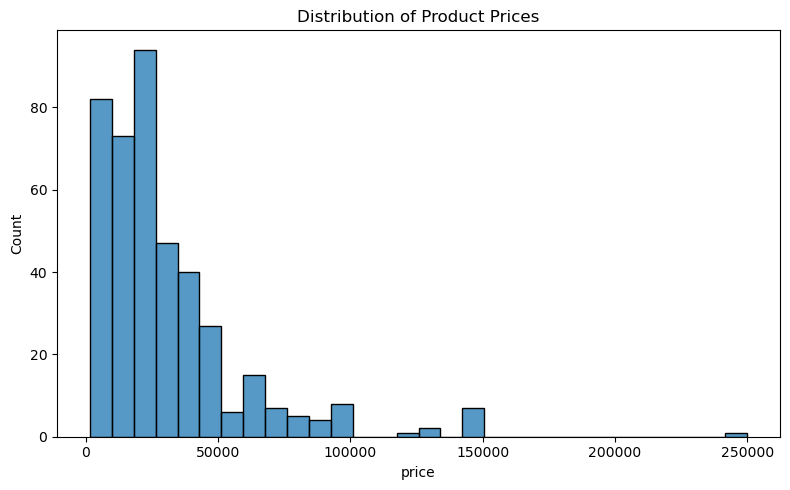

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["price"],
    bins=30
)

plt.title(
    "Distribution of Product Prices"
)

plt.tight_layout()

plt.show()

## Correlation Analysis

In [14]:
corr_cols = [

    "price",

    "number_sold",

    "rating",

    "number_of_reviews",

    "estimated_revenue"
]

corr = (
    df[corr_cols]
    .corr()
)

corr

,price,number_sold,rating,number_of_reviews,estimated_revenue
price,1.000000,-0.040121,-0.040656,-0.099971,0.151531
number_sold,-0.040121,1.000000,0.090098,0.254023,0.869171
rating,-0.040656,0.090098,1.000000,0.148039,0.089979
number_of_reviews,-0.099971,0.254023,0.148039,1.000000,0.140989
estimated_revenue,0.151531,0.869171,0.089979,0.140989,1.000000


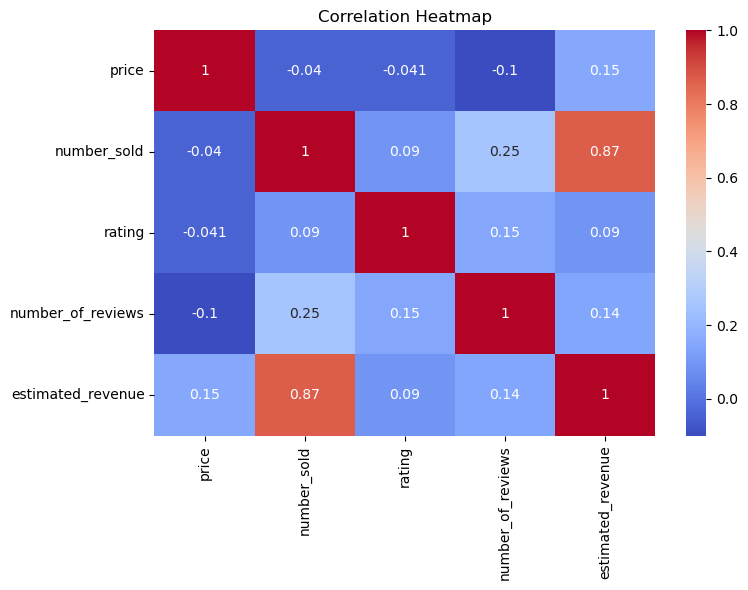

In [15]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Correlation Heatmap"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
print("="*50)
print("KEY RESULTS")
print("="*50)

print(
    f"Total Estimated Revenue: Rp {df['estimated_revenue'].sum():,.0f}"
)

print("\nTop Variety by Revenue:")
print(
    variety_stats.head(1)
)

print("\nTop Location by Revenue:")
print(
    location_stats.head(1)
)

KEY RESULTS
Total Estimated Revenue: Rp 46,587,163

Top Variety by Revenue:
          listings  sales   revenue
variety                            
Compacta        17    271  11653000

Top Location by Revenue:
              listings  sales   revenue
location                               
Kab. Cianjur        21    313  12245000
